# 1. VaR 和 ES：用"排卡片"来理解

**这一本要回答的问题：** 我们这个 100 万美元的组合（SPY 40%、QQQ 30%、TLT 20%、GLD 10%），"明天最坏大概会亏多少？"

**怎么用：**
- 从上往下，一个单元格一个单元格按 `Shift + Enter` 运行。
- 标着 🎛️ 的地方是让你动手改的：可以拖滑块，也可以直接改代码里的数字再运行。
- 顺序是：**先讲直觉 → 再用真实数据算一遍 → 最后才看公式**。公式放在最后，到那时你应该已经知道它在说什么了。

所有数字都是用仓库里的真实数据（`data/raw/prices.csv`，2006–2025）和仓库里的函数（`src/mre/risk/var.py`）现算出来的。

## 第 1 步：直觉

想象一下：把过去 20 年**每一天**这个组合的盈亏写在一张卡片上，一共大约 5000 张。然后从"亏得最多"到"赚得最多"排成一排。

- **VaR 99%（在险价值）**：从最惨的一端开始数，数到 **1%** 的位置（5000 张的 1% 大约是第 50 张）。那张卡片上的亏损，就是 99% VaR。
  它的意思是："100 天里大约只有 1 天，会亏得比这个数还多。"
- **ES 99%（期望损失，Expected Shortfall）**：把那最惨的 1%（大约 50 张卡片）上的亏损**全部加起来求平均**。
  它的意思是："如果真的碰上了那 1% 的坏日子，平均会亏多少。"

一句话记住：**VaR 是一道门槛，ES 是门槛后面的平均深度。** VaR 只告诉你门在哪，ES 还告诉你门后面的坑有多深。

下面我们就真的把卡片排一排。

In [1]:
from learn_utils import *
from mre.risk.var import historical_var, historical_es

cfg, asset_rets, port = load_portfolio()
V = cfg.portfolio_value          # 组合市值：1,000,000 美元
pnl = port * V                   # 每天的盈亏（美元）。正数 = 赚钱，负数 = 亏钱

print(f"一共 {len(pnl)} 天，从 {pnl.index[0].date()} 到 {pnl.index[-1].date()}")
print(f"组合权重：{cfg.weights}，市值 {money(V)}")

一共 5030 天，从 2006-01-04 到 2025-12-31
组合权重：{'SPY': 0.4, 'QQQ': 0.3, 'TLT': 0.2, 'GLD': 0.1}，市值 $1,000,000


## 第 2 步：把卡片排一排，看最惨的那几张

In [2]:
cards = pnl.sort_values()        # 从亏得最多到赚得最多排好
worst = pd.DataFrame({
    "日期": cards.index[:10].date,
    "当天盈亏": [money(x) for x in cards.values[:10]],
    "收益率": [f"{x / V:.2%}" for x in cards.values[:10]],
}, index=range(1, 11))
worst.index.name = "第几惨"
worst

,日期,当天盈亏,收益率
第几惨,,,
1,2020-03-12,"-$68,528",-6.85%
2,2020-03-16,"-$67,898",-6.79%
3,2008-10-15,"-$62,983",-6.30%
4,2008-12-01,"-$56,136",-5.61%
5,2020-03-09,"-$46,492",-4.65%
6,2008-09-29,"-$45,950",-4.60%
7,2020-03-18,"-$42,653",-4.27%
8,2025-04-04,"-$42,212",-4.22%
9,2020-03-11,"-$40,281",-4.03%


最惨的 10 天里，大部分集中在 2008 年金融危机和 2020 年 3 月新冠暴跌——坏日子是扎堆来的，这一点在第 2 本 notebook（波动率）里会变得很重要。

### 现在数到 1% 的位置

5030 张卡片的 1% 是 50.3 张。卡片是一张一张的，"第 50.3 张"不存在，所以 numpy 会在两张相邻卡片之间**按比例插值**（仓库用的是 `linear` 插值）。下面直接把那附近的几张卡片列出来：

In [3]:
alpha = 0.99                     # 置信水平：99%
N = len(cards)
pos = (N - 1) * (1 - alpha)      # numpy 线性插值时的"位置"（从 0 开始数）
lo = int(np.floor(pos))
print(f"位置 = (N - 1) x 1% = {pos:.2f}，也就是第 {lo + 1} 张和第 {lo + 2} 张卡片之间（从 1 开始数）")
for k in range(lo - 1, lo + 3):
    print(f"  第 {k + 1:>2} 张卡片: {money(cards.values[k])}")

# 手算插值：在第 lo+1 和 lo+2 张之间，按小数部分取比例
frac = pos - lo
manual_var = -(cards.values[lo] + frac * (cards.values[lo + 1] - cards.values[lo]))
repo_var = historical_var(pnl, alpha)          # 仓库里的函数
print(f"\n手算 VaR 99%  = {money(manual_var)}")
print(f"仓库函数结果 = {money(repo_var)}   （两者一致）")

位置 = (N - 1) x 1% = 50.29，也就是第 51 张和第 52 张卡片之间（从 1 开始数）
  第 50 张卡片: -$24,312
  第 51 张卡片: -$24,234
  第 52 张卡片: -$24,108
  第 53 张卡片: -$23,925

手算 VaR 99%  = $24,197
仓库函数结果 = $24,197   （两者一致）


### 再算 ES：门槛后面所有卡片的平均

In [4]:
tail = cards[cards <= -repo_var]               # 亏损达到或超过 VaR 的所有卡片
manual_es = -tail.mean()
print(f"亏损 >= VaR 的卡片有 {len(tail)} 张")
print(f"它们的平均亏损（手算 ES 99%） = {money(manual_es)}")
print(f"仓库函数 historical_es        = {money(historical_es(pnl, alpha))}")
print(f"\nES / VaR = {manual_es / repo_var:.2f}：真碰上坏日子，平均比门槛还多亏 {manual_es / repo_var - 1:.0%}")

亏损 >= VaR 的卡片有 51 张
它们的平均亏损（手算 ES 99%） = $34,116
仓库函数 historical_es        = $34,116

ES / VaR = 1.41：真碰上坏日子，平均比门槛还多亏 41%


这两个数（VaR 约 \$24,197，ES 约 \$34,116）和仓库 `reports/phase1_report.md` 里的 Historical 99% 那一行完全一样。你刚才等于是亲手重做了 Phase 1 的核心计算。

## 第 3 步：画出来看

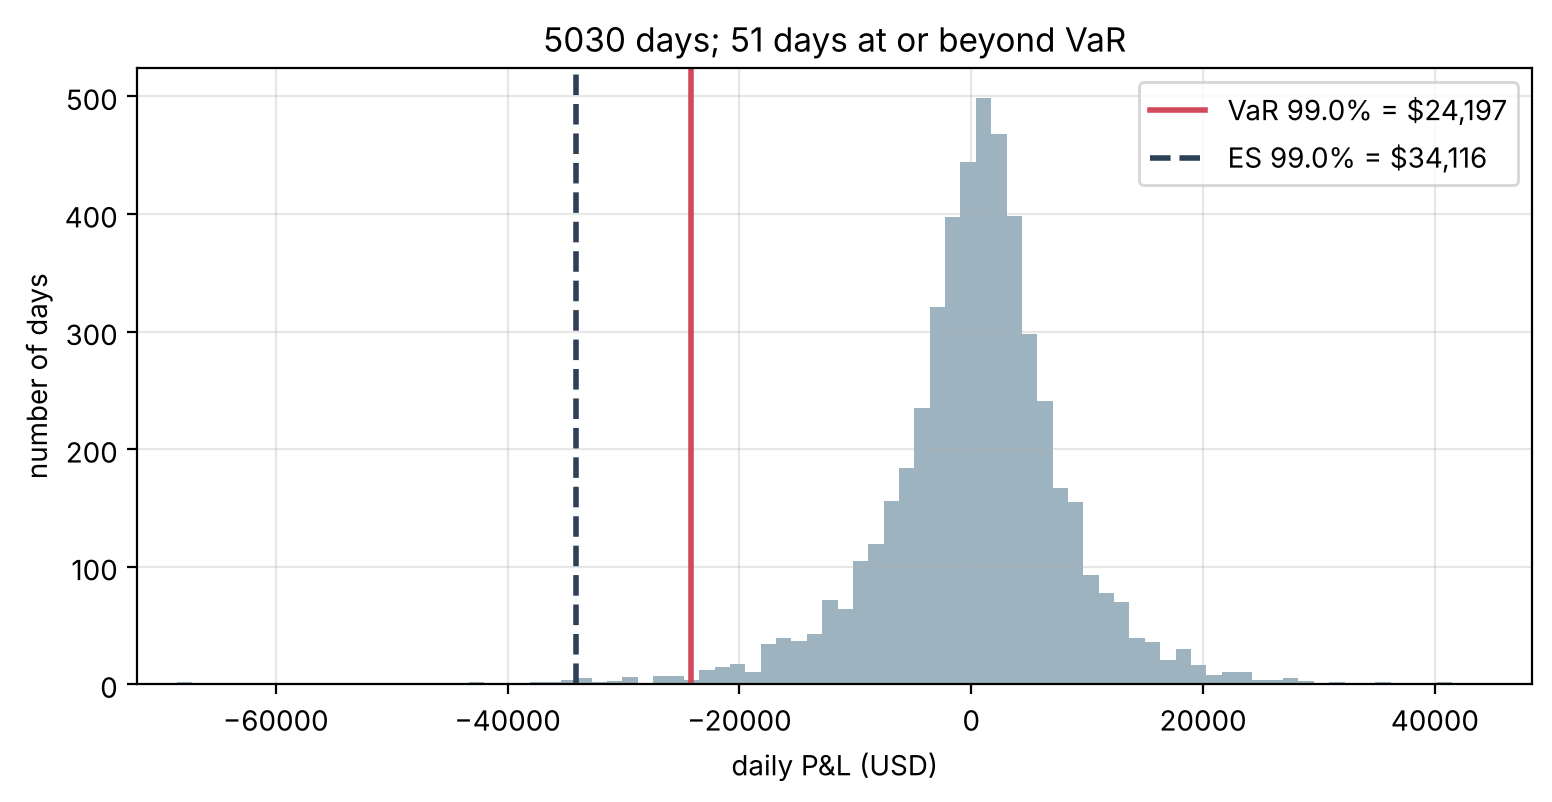

In [5]:
def show_tail(alpha=0.99, window="全部 20 年"):
    data = {"全部 20 年": pnl, "最近 500 天": pnl.iloc[-500:], "最近 250 天": pnl.iloc[-250:]}[window]
    var, es = historical_var(data, alpha), historical_es(data, alpha)
    n_beyond = int((data <= -var).sum())

    fig, ax = plt.subplots()
    ax.hist(data, bins=120, color="#9db4c0")
    ax.axvline(-var, color="#d1495b", lw=2, label=f"VaR {alpha:.1%} = {money(var)}")
    ax.axvline(-es, color="#2e4057", lw=2, ls="--", label=f"ES {alpha:.1%} = {money(es)}")
    ax.set_xlim(min(data.min(), -es) * 1.05, -data.quantile(0.01) * 2)  # 右边截掉，重点看左尾
    ax.set_xlabel("daily P&L (USD)"); ax.set_ylabel("number of days")
    ax.set_title(f"{len(data)} days; {n_beyond} days at or beyond VaR")
    ax.legend(); plt.show()

show_tail(0.99, "全部 20 年")

红线左边的那一小撮就是"门槛后面的坏日子"，ES（虚线）是它们的平均位置，所以 ES 总是在 VaR 的左边（亏得更多）。

### 🎛️ 你来调

拖动滑块（或者直接改上面最后一行 `show_tail(0.99, "全部 20 年")` 里的数字），试着回答：
1. 把置信水平从 95% 拉到 99.5%，VaR 和 ES 怎么变？它们之间的差距是变大还是变小？
2. 换成"最近 500 天"，VaR 比 20 年全样本大还是小？为什么？（提示：最近 500 天里有没有 2008 和 2020？）

（在 Jupyter 里这里是滑块。静态版本里换成下面几组参数各跑一遍。）

▶ alpha = 0.95，window = 全部 20 年


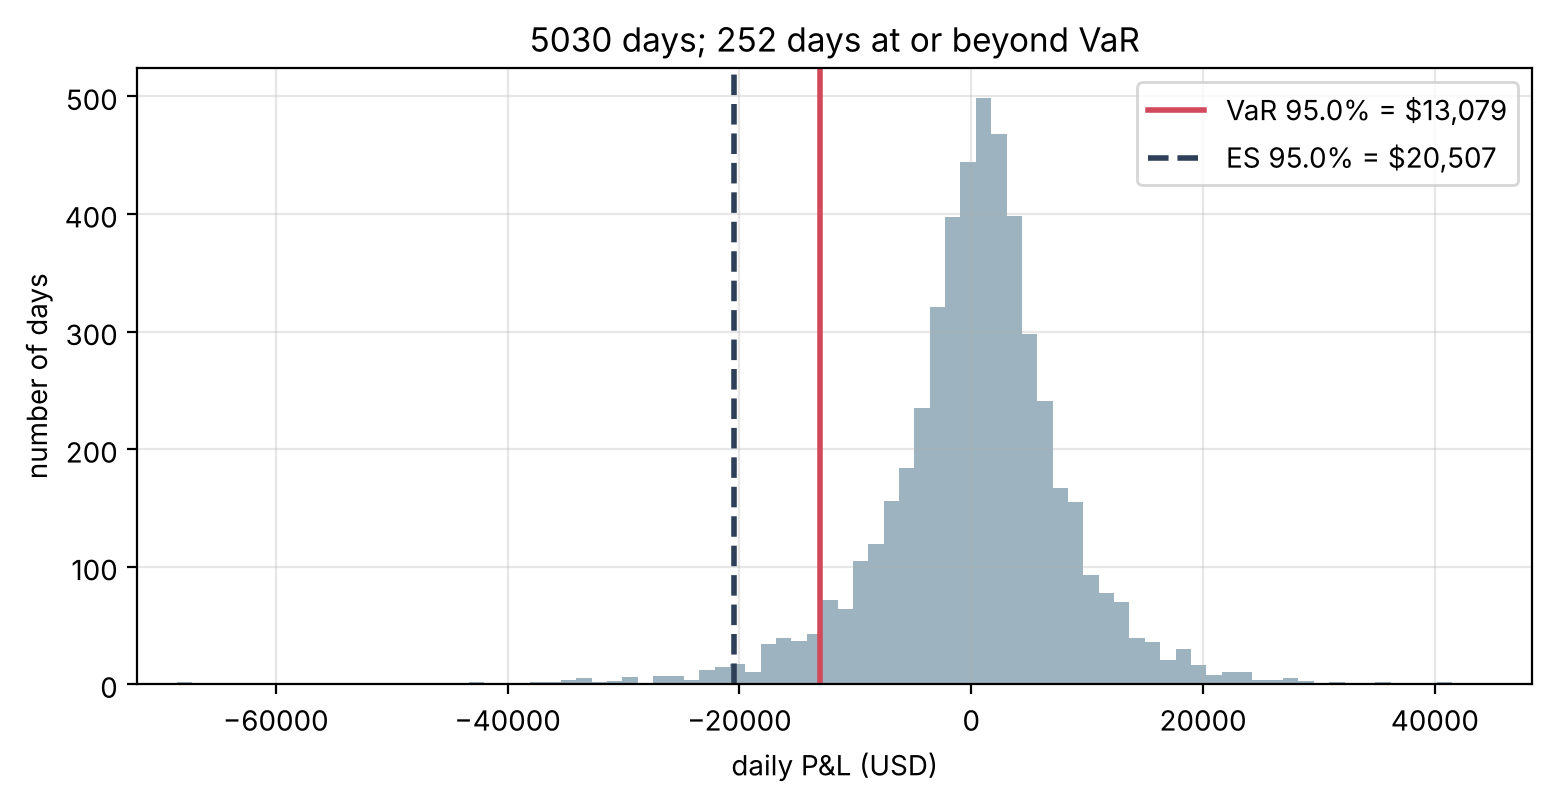


▶ alpha = 0.99，window = 最近 500 天


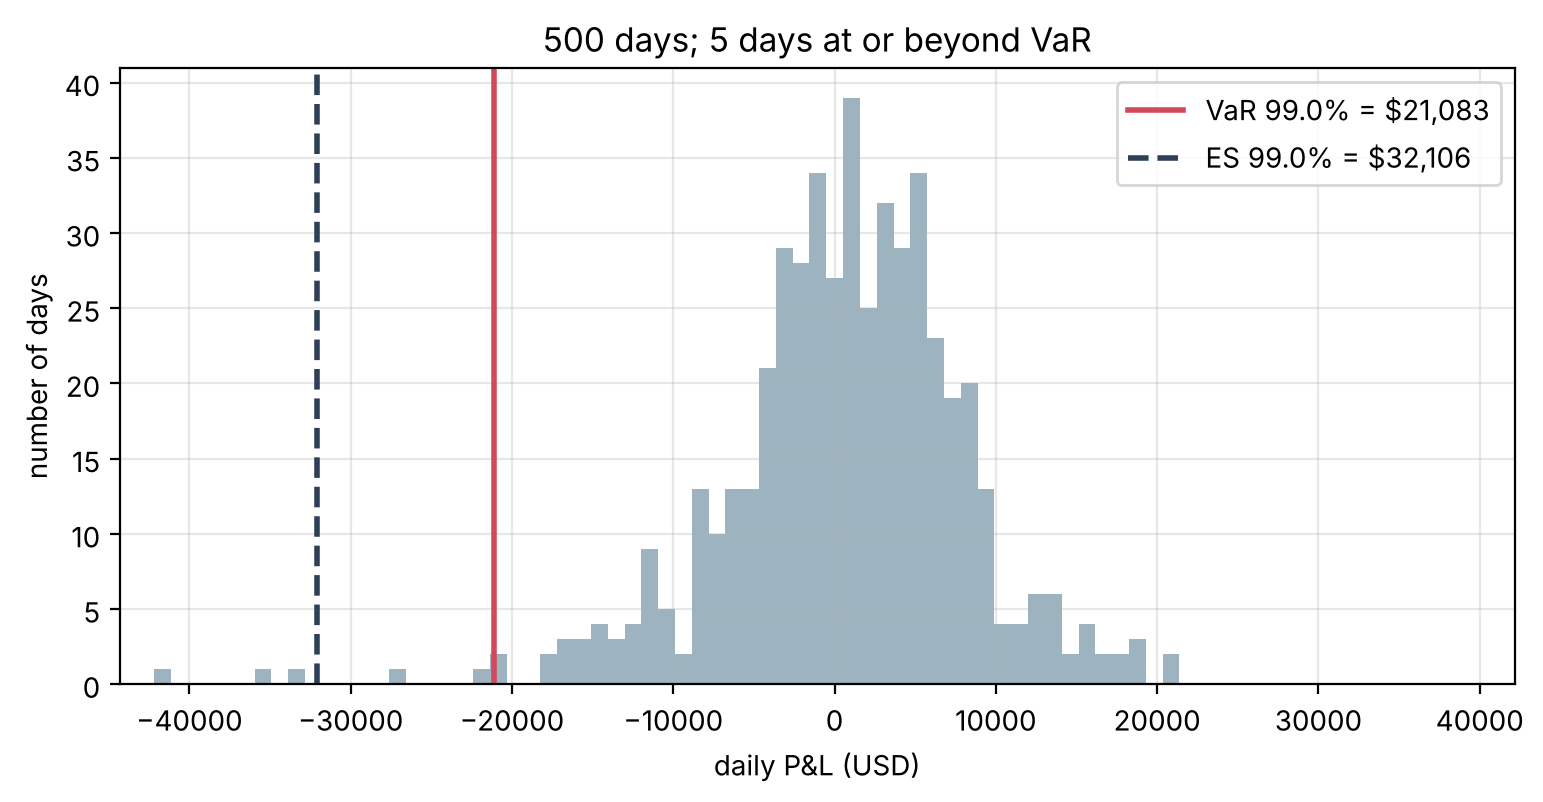

In [6]:
play(show_tail, examples=[{"alpha": 0.95, "window": "全部 20 年"}, {"alpha": 0.99, "window": "最近 500 天"}],
     alpha=(0.90, 0.995, 0.005), window=["全部 20 年", "最近 500 天", "最近 250 天"])

不想拖滑块的话，下面这张表一次把几个常见的置信水平都算出来：

In [7]:
rows = []
for a in [0.90, 0.95, 0.975, 0.99, 0.995]:
    var, es = historical_var(pnl, a), historical_es(pnl, a)
    rows.append({"置信水平": f"{a:.1%}", "VaR": money(var), "ES": money(es),
                 "ES/VaR": round(es / var, 2), "超过 VaR 的天数": int((pnl < -var).sum())})
pd.DataFrame(rows)

,置信水平,VaR,ES,ES/VaR,超过 VaR 的天数
0,90.0%,"$8,857","$15,614",1.76,503
1,95.0%,"$13,079","$20,507",1.57,252
2,97.5%,"$17,533","$25,828",1.47,126
3,99.0%,"$24,197","$34,116",1.41,51
4,99.5%,"$30,875","$40,769",1.32,26


"超过 VaR 的天数"几乎正好等于 天数 × (1 − 置信水平)。这不是巧合：VaR 就是这么"数"出来的，所以在**同一段数据上**检查它一定准。真正的考验是拿它去预测**以后**的日子——这就是第 4 本 notebook 的回测。

## 第 4 步：VaR 看不见门后面有多深

做一个思想实验：假设历史上最惨的那 10 天，每天都亏成原来的 3 倍。VaR 会变吗？ES 呢？

In [8]:
def deepen_tail(k_worst=10, factor=3.0, alpha=0.99):
    worse = pnl.copy()
    idx = pnl.nsmallest(k_worst).index
    worse[idx] = pnl[idx] * factor                 # 只把最惨的 k 天放大
    print(f"把最惨的 {k_worst} 天放大 {factor} 倍：")
    print(f"  VaR {alpha:.0%}: {money(historical_var(pnl, alpha)):>10} -> {money(historical_var(worse, alpha)):>10}")
    print(f"  ES  {alpha:.0%}: {money(historical_es(pnl, alpha)):>10} -> {money(historical_es(worse, alpha)):>10}")

deepen_tail(10, 3.0)

把最惨的 10 天放大 3.0 倍：
  VaR 99%:    $24,197 ->    $24,197
  ES  99%:    $34,116 ->    $54,162


VaR 一分钱都没变，ES 明显变大了。因为 VaR 只看"第 50 张卡片"，至于前面 49 张有多惨，它根本不在乎。
这就是监管后来更偏爱 ES 的原因之一（另一个原因"次可加性"在第 5 本 notebook）。

🎛️ 试试：把 `k_worst` 调到 60（超过了 1% 的 50 张），VaR 还会不变吗？

In [9]:
play(deepen_tail, examples=[{"k_worst": 60, "factor": 3.0, "alpha": 0.99}],
     k_worst=(1, 100, 1), factor=(1.0, 5.0, 0.5), alpha=[0.95, 0.99])

（在 Jupyter 里这里是滑块。静态版本里换成下面几组参数各跑一遍。）

▶ k_worst = 60，factor = 3.0，alpha = 0.99
把最惨的 60 天放大 3.0 倍：
  VaR 99%:    $24,197 ->    $72,591
  ES  99%:    $34,116 ->   $102,348


## 最后：公式（现在再看就不难了）

先把要用的符号用大白话定义一遍：

| 符号 | 意思 |
|---|---|
| $X$ | 某一天的盈亏（正数 = 赚） |
| $\alpha$ | 置信水平，比如 0.99 |
| $q_{1-\alpha}(X)$ | 把所有天的 $X$ 从小到大排好，数到 $1-\alpha$（比如 1%）那个位置的值，叫"分位数" |

VaR 就是"那张卡片上的亏损"，因为卡片上写的是负数，所以前面加个负号变成正的损失：

$$\text{VaR}_\alpha = -\,q_{1-\alpha}(X)$$

ES 就是"门槛后面所有卡片的平均"，同样加负号：

$$\text{ES}_\alpha = -\,\text{平均}\big(X \;\big|\; X \le -\text{VaR}_\alpha\big)$$

竖线 $|$ 读作"在……的条件下"，也就是"只看满足后面条件的那些天"。

**对应代码：** `src/mre/risk/var.py` 里的 `historical_var`（一行 `np.quantile`）和 `historical_es`（挑出尾部取平均）。你可以打开看看，现在应该一眼就能看懂。

## 小练习

1. 95% VaR 大约是第几张卡片？
2. 如果明天的市场和过去 20 年完全不一样（比如出现从没见过的暴跌），历史模拟法会有什么问题？
3. 为什么 ES 一定 ≥ VaR？

<details><summary>点这里看参考答案</summary>

1. 5030 × 5% ≈ 251.5，所以在第 252 张左右。
2. 历史模拟只会"复读"过去出现过的日子，没见过的暴跌它给不出来；而且它对 20 年前和昨天一视同仁，反应很慢。第 2、3 本 notebook 的 EWMA / GARCH / FHS 就是为了解决"反应慢"。
3. ES 是门槛后面那些亏损的平均，而门槛后面每一天的亏损都 ≥ VaR，平均值自然也 ≥ VaR。
</details>